# 04 · Forecasting weekly PM2.5
**Plan (Box-Jenkins, Lecture 29).** Identify candidate models → estimate → check the residuals → forecast → evaluate on data the model has not seen.

1. **Identification** of a SARIMA model on the training years (AIC/BIC table and residual diagnostics).
2. **Backtest.** Five models and an equal-weight combination forecast 52 weeks ahead from three forecast origins:
   end of 2016 → forecast 2017; end of 2017 → forecast 2018; end of 2018 → forecast 2019. Each model is refitted, with every choice
   (orders, number of harmonics) made by AIC, using **only data before the origin**.
3. **Accuracy** (ME, MAE, RMSE, MAPE), interval coverage and the Diebold-Mariano test (Lecture 30).
4. **One week ahead:** does last week's weather improve the forecast error?
5. **2020 as a "what if" check:** forecasts made at the end of 2019, compared with what happened in 2020.

All models work on **log PM2.5**. The point forecast is exp(μ), the **median** of PM2.5 (the log model's mean would be exp(μ + σ²/2)).
Errors are always computed on the original µg/m³ scale as *actual − forecast*.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"
import sys
sys.path.append("..")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

from src import forecast as F
from src.data import PROCESSED, RESULTS
from src.tsa import week_index, doy_anomaly
from src.plots import use_style, savefig, BLUE, ORANGE, AQUA, NEUTRAL, INK_2, MUTED

warnings.filterwarnings("ignore")
use_style()
weekly = pd.read_csv(PROCESSED / "delhi_weekly.csv", index_col="Date", parse_dates=True)
daily = pd.read_csv(PROCESSED / "delhi_daily.csv", index_col="Date", parse_dates=True).asfreq("D")
y, raw = weekly["log_pm25"], weekly["pm25"]
key = {}
print(len(weekly), "weekly values; origins:", F.ORIGINS)

287 weekly values; origins: {2017: '2016-12-25', 2018: '2017-12-31', 2019: '2018-12-30'}


## 1. Identification: which SARIMA?
Training years 2015-2018 (209 weeks), log scale, seasonal period s = 52. Following the Lecture 21 hands-on we compare a non-seasonal benchmark
(A), a seasonal-only model (B) and combined models (C, D). **AIC/BIC are only comparable between models with the same differencing and
data**; the lectures compare A-C anyway and warn that "no single metric tells the whole story", so we also look at the residuals.

In [2]:
y_tr = y.loc[:"2018-12-30"]
cands = {"A: ARIMA(0,1,1)": ((0, 1, 1), (0, 0, 0, 0)),
         "B: ARIMA(0,0,0)(0,1,1)52": ((0, 0, 0), (0, 1, 1, 52)),
         "C: ARIMA(0,1,1)(0,1,1)52": ((0, 1, 1), (0, 1, 1, 52)),
         "D: ARIMA(1,0,1)(0,1,1)52": ((1, 0, 1), (0, 1, 1, 52))}
fits, rows = {}, []
for name, (o, so) in cands.items():
    r = F._fit(SARIMAX(y_tr, order=o, seasonal_order=so, trend="n"))
    fits[name] = r
    rows.append({"model": name, "AIC": r.aic, "BIC": r.bic, "k": len(r.params), "burn_in_residuals": int(r.loglikelihood_burn)})
ident = pd.DataFrame(rows).set_index("model"); ident.round(1).to_csv(RESULTS / "fc_sarima_identification.csv")
ident.round(1)

,AIC,BIC,k,burn_in_residuals
model,,,,
"A: ARIMA(0,1,1)",79.9,86.5,2,1
"B: ARIMA(0,0,0)(0,1,1)52",73.2,79.3,2,52
"C: ARIMA(0,1,1)(0,1,1)52",45.2,54.3,3,53
"D: ARIMA(1,0,1)(0,1,1)52",39.4,51.7,4,52


## 2. Residual check of the SARIMA model (Ljung-Box, Lecture 29)
For a model with a seasonal difference the state-space fit starts with a **diffuse** prior on the first 52 seasonal states
(it has no earlier year to difference against), so the first 52 "residuals" simply equal the series level; they are **not** one-step prediction errors
and must be dropped before testing for autocorrelation. If they are kept, Ljung-Box shows p ≈ 0 at every lag, which would wrongly suggest the model is useless.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


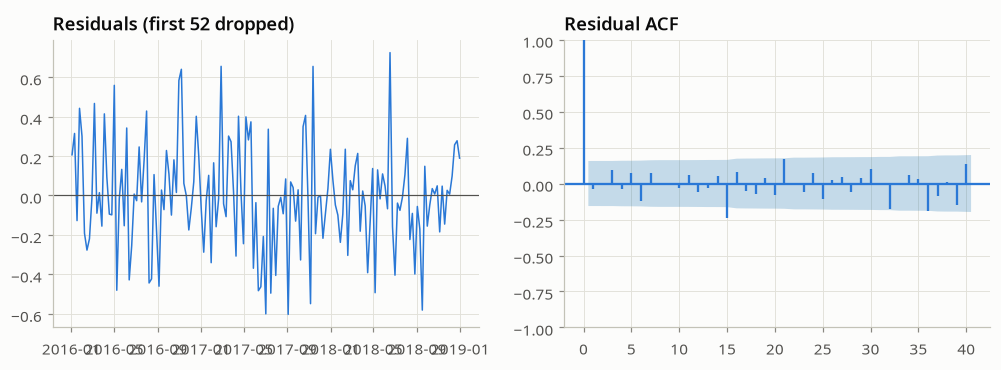

seasonal MA coefficient: -0.988 +/- 8.3


,"p-value, all residuals","p-value, first 52 dropped"
Ljung-Box lag,,
10,0.0,0.5973
26,0.0,0.1326
52,0.0,0.0201


In [3]:
rD = fits["D: ARIMA(1,0,1)(0,1,1)52"]
burn = int(rD.loglikelihood_burn)
e_all = pd.Series(np.asarray(rD.resid), index=y_tr.index)
e = e_all.iloc[burn:]
lb_all = acorr_ljungbox(e_all, lags=[10, 26, 52], model_df=2, return_df=True)["lb_pvalue"]
lb = acorr_ljungbox(e, lags=[10, 26, 52], model_df=2, return_df=True)["lb_pvalue"]
diag = pd.DataFrame({"p-value, all residuals": lb_all.values, "p-value, first 52 dropped": lb.values}, index=pd.Index([10, 26, 52], name="Ljung-Box lag"))
diag.round(4).to_csv(RESULTS / "fc_sarima_ljungbox.csv")
sma = float(rD.params["ma.S.L52"]); sma_se = float(rD.bse["ma.S.L52"])
key["sarima_seasonal_ma"], key["sarima_seasonal_ma_se"] = round(sma, 3), round(sma_se, 1)
key["lb_all_lag10"], key["lb_drop_lag10"], key["lb_drop_lag26"], key["lb_drop_lag52"] = [round(float(x), 3) for x in (lb_all[10], lb[10], lb[26], lb[52])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(e.index, e, color=BLUE, lw=1); axes[0].axhline(0, color=INK_2, lw=0.8); axes[0].set_title("Residuals (first 52 dropped)")
plot_acf(e, lags=40, ax=axes[1], marker=None, color=BLUE, vlines_kwargs={"colors": BLUE}, title="Residual ACF")
savefig(fig, "08b_sarima_residuals"); plt.show()
print("seasonal MA coefficient:", round(sma, 3), "+/-", round(sma_se, 1)); diag.round(4)

**Reading it.** Without the first 52 residuals the Ljung-Box test passes at lags 10 and 26 but fails at lag 52. More importantly the seasonal moving-average coefficient
Θ is about **−1**, i.e. on the boundary of invertibility, with a huge standard error: the data do not identify it. A seasonal MA(1) coefficient near −1 is the textbook
sign of **over-differencing**: taking $\nabla_{52}$ of a series whose seasonal pattern is already *fixed* from year to year injects an artificial
moving-average term. This is why we also fit a model that describes the yearly pattern **directly** (harmonic regression) rather than differencing it away.

## 3. The models
All are fitted to log PM2.5 using only the training window of each fold.

| Model | Idea | Lecture |
|---|---|---|
| **Seasonal naive** | forecast = the value of the same week one year ago | benchmark |
| **Seasonal mean** | forecast = the average log PM2.5 of that calendar week over *all* training years (each year contributes, so noise is averaged out) | classical decomposition (06) |
| **Holt-Winters** | exponentially weighted level + seasonal index (+ optional damped trend), additive on the log scale; trend option chosen by AIC | 22-23 |
| **SARIMA** | $(p,0,q)(P,1,Q)_{52}$, orders chosen by AIC from a small grid | 20-21, 29 |
| **Harmonic regression** | a smooth yearly curve $c+\sum_{k\le K}[a_k\sin\frac{2\pi kt}{m}+b_k\cos\frac{2\pi kt}{m}]$ plus ARMA(p,q) errors; $K\le5$ and $(p,q)$ chosen by AIC | regression with autocorrelated errors (13-16), Fourier series |
| **Combination** | simple average of the log forecasts of the seasonal mean, Holt-Winters, SARIMA and harmonic regression | 30 |

The yearly shape of the harmonic model has only $2K$ parameters, so it is a *smooth summary* of the pattern, not a copy of the past values
(unlike the seasonal naive forecast, which repeats last year's noise).

In [4]:
models = {"Seasonal naive": F.seasonal_naive, "Seasonal mean": F.seasonal_mean, "Holt-Winters": F.holt_winters,
          "SARIMA": F.sarima_auto, "Harmonic regression": F.harmonic}
bt, fcs = F.backtest(y, raw, models, n_jobs=8)
# equal-weight combination (point forecast only)
COMB = ["Seasonal mean", "Holt-Winters", "SARIMA", "Harmonic regression"]
extra = []
for fold in fcs:
    c = F.combine(fcs[fold], COMB)
    fcs[fold]["Combination"] = {**c, "idx": fcs[fold]["Seasonal mean"]["idx"], "actual": fcs[fold]["Seasonal mean"]["actual"]}
    extra.append({"fold": fold, "model": "Combination", "n_train": 0, **F.metrics(fcs[fold]["Combination"]["actual"], c["mu"])})
bt = pd.concat([bt, pd.DataFrame(extra)], ignore_index=True)
ORDER = ["Seasonal naive", "Seasonal mean", "Holt-Winters", "SARIMA", "Harmonic regression", "Combination"]
bt.to_csv(RESULTS / "fc_backtest_metrics.csv", index=False)
pd.DataFrame([{"fold": f, "model": m, "date": d, "mu": mu, "sd": (np.nan if o["sd"] is None else s), "actual": a}
              for f, mm in fcs.items() for m, o in mm.items()
              for d, mu, s, a in zip(o["idx"], o["mu"], (o["sd"] if o["sd"] is not None else np.full(len(o["mu"]), np.nan)), o["actual"])]
             ).to_csv(RESULTS / "fc_backtest_forecasts.csv", index=False)
specs = {f: {m: o.get("spec") for m, o in mm.items() if o.get("spec")} for f, mm in fcs.items()}
pd.DataFrame([{"fold": f, "model": m, **sp} for f, mm in specs.items() for m, sp in mm.items()]).to_csv(RESULTS / "fc_specs.csv", index=False)
print(pd.DataFrame([{"fold": f, "model": m, **sp} for f, mm in specs.items() for m, sp in mm.items()]).to_string())

/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Musi

/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Musi

/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Musi

/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Musi

... (86 outputs left out)

/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
/home/kushagrasingh/Music/time_anal_proj/.venv/lib64/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


2017 Seasonal naive 38.4
2017 Seasonal mean 31.0
2017 Holt-Winters 51.5
2017 SARIMA 72.3
2017 Harmonic regression 30.1
2018 Seasonal naive 29.0
2018 Seasonal mean 21.8
2018 Holt-Winters 24.2
2018 SARIMA 21.1
2018 Harmonic regression 23.4
2019 Seasonal naive 30.3
2019 Seasonal mean 27.8
2019 Holt-Winters 34.3
2019 SARIMA 27.5
2019 Harmonic regression 27.6
   fold                model trend     alpha     gamma    p    q    P    Q  n_rejected    K
0  2017         Holt-Winters  none  0.227893  0.013224  NaN  NaN  NaN  NaN         NaN  NaN
1  2017               SARIMA   NaN       NaN       NaN  1.0  0.0  1.0  0.0         0.0  NaN
2  2017  Harmonic regression   NaN       NaN       NaN  1.0  0.0  NaN  NaN         0.0  5.0
3  2018         Holt-Winters  none  0.251958  0.000075  NaN  NaN  NaN  NaN         NaN  NaN
4  2018               SARIMA   NaN       NaN       NaN  1.0  1.0  0.0  1.0         0.0  NaN
5  2018  Harmonic regression   NaN       NaN       NaN  1.0  1.0  NaN  NaN         0.0  5.0

## 4. Accuracy (original µg/m³ scale; errors = actual − forecast)
**ME** = mean error (bias: positive means we under-predict), **MAE** = mean absolute error, **RMSE** = root mean squared error,
**MAPE** = mean absolute percentage error (Lecture 30).

In [5]:
def pivot(col):
    t = bt.pivot(index="model", columns="fold", values=col).loc[ORDER]
    t["mean 2018-19"] = t[[2018, 2019]].mean(axis=1); t["mean 2017-19"] = t[[2017, 2018, 2019]].mean(axis=1)
    return t
mae, rmse, me, mape = pivot("MAE"), pivot("RMSE"), pivot("ME"), pivot("MAPE")
mae.round(1).to_csv(RESULTS / "fc_backtest_mae.csv"); rmse.round(1).to_csv(RESULTS / "fc_backtest_rmse.csv")
me.round(1).to_csv(RESULTS / "fc_backtest_me.csv"); mape.round(1).to_csv(RESULTS / "fc_backtest_mape.csv")
cov = bt.pivot(index="model", columns="fold", values="coverage").loc[ORDER]
width = bt.pivot(index="model", columns="fold", values="width").loc[ORDER]
cov.round(3).to_csv(RESULTS / "fc_coverage.csv"); width.round(1).to_csv(RESULTS / "fc_width.csv")
print("MAE"); display(mae.round(1)); print("ME (bias)"); display(me.round(1)); print("coverage of the 95% intervals"); display(cov.round(2))

MAE


fold,2017,2018,2019,mean 2018-19,mean 2017-19
model,,,,,
Seasonal naive,38.4,29.0,30.3,29.6,32.6
Seasonal mean,31.0,21.8,27.8,24.8,26.9
Holt-Winters,51.5,24.2,34.3,29.2,36.6
SARIMA,72.3,21.1,27.5,24.3,40.3
Harmonic regression,30.1,23.4,27.6,25.5,27.0
Combination,39.6,21.1,28.3,24.7,29.6


ME (bias)


fold,2017,2018,2019,mean 2018-19,mean 2017-19
model,,,,,
Seasonal naive,-13.6,-9.9,-6.4,-8.1,-9.9
Seasonal mean,-1.2,-9.1,-12.6,-10.8,-7.6
Holt-Winters,-36.6,-9.4,-26.7,-18.0,-24.2
SARIMA,-50.6,-8.7,-14.7,-11.7,-24.6
Harmonic regression,-0.9,-8.4,-13.8,-11.1,-7.7
Combination,-17.6,-8.5,-16.5,-12.5,-14.2


coverage of the 95% intervals


fold,2017,2018,2019
model,,,
Seasonal naive,0.88,0.94,0.92
Seasonal mean,0.62,0.92,0.81
Holt-Winters,0.81,0.96,0.87
SARIMA,0.23,0.94,0.85
Harmonic regression,0.67,0.94,0.87
Combination,NaN,NaN,NaN


## 5. Is any model significantly better than the seasonal mean? Diebold-Mariano (Lecture 30)
Loss differential $d_t = |e_t^{a}| - |e_t^{b}|$ for model *a* against the seasonal mean *b*; $H_0: E(d_t)=0$ (equal accuracy).
The weekly errors of a 52-step forecast are strongly autocorrelated, so the long-run variance uses a Bartlett kernel with 12 lags (a quarter-year).
We pool the two later forecast years (2018, 2019); 2017 only had two training years. As a **robustness check** we also report a moving-block bootstrap
interval for the same mean difference (blocks of 8 weeks drawn within each year).

In [6]:
def abs_err(model, folds):
    return [np.abs(fcs[f][model]["actual"] - np.exp(fcs[f][model]["mu"])) for f in folds]
rows = []
for m in ORDER:
    if m == "Seasonal mean":
        continue
    ea = np.concatenate([fcs[f][m]["actual"] - np.exp(fcs[f][m]["mu"]) for f in (2018, 2019)])
    eb = np.concatenate([fcs[f]["Seasonal mean"]["actual"] - np.exp(fcs[f]["Seasonal mean"]["mu"]) for f in (2018, 2019)])
    dbar, dm, p = F.dm_test(ea, eb, lag=12)
    bd, lo, hi = F.block_bootstrap_diff(abs_err(m, (2018, 2019)), abs_err("Seasonal mean", (2018, 2019)), block=8, n=4000)
    rows.append({"model": m, "mean MAE difference vs seasonal mean": dbar, "DM": dm, "DM p-value": p, "bootstrap lo95": lo, "bootstrap hi95": hi})
dmt = pd.DataFrame(rows).set_index("model"); dmt.round(3).to_csv(RESULTS / "fc_dm.csv"); dmt.round(3)

,mean MAE difference vs seasonal mean,DM,DM p-value,bootstrap lo95,bootstrap hi95
model,,,,,
Seasonal naive,4.841,2.210,0.027,0.937,8.964
Holt-Winters,4.422,3.312,0.001,2.431,6.505
SARIMA,-0.527,-0.689,0.491,-1.911,0.981
Harmonic regression,0.730,0.529,0.597,-1.938,3.641
Combination,-0.137,-0.268,0.789,-1.132,0.838


A negative difference means the model has *lower* error than the seasonal mean. Only differences whose p-value is below 0.05 (and whose bootstrap interval excludes 0) count as real.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


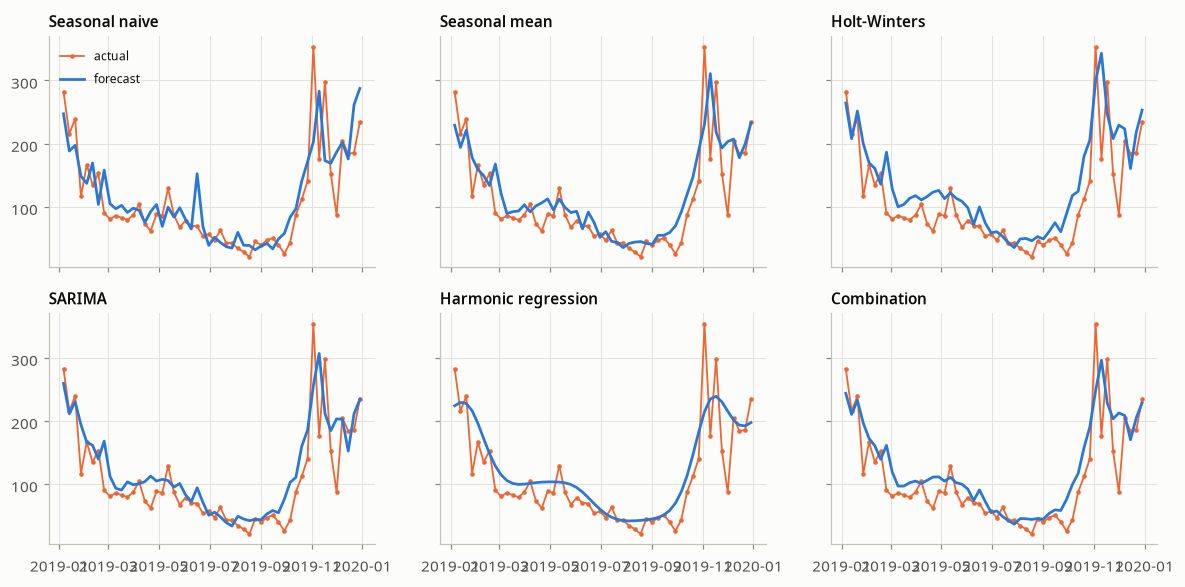

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), ORDER):
    o = fcs[2019][m]
    ax.plot(o["idx"], o["actual"], color=ORANGE, lw=1.2, marker="o", ms=2, label="actual")
    ax.plot(o["idx"], np.exp(o["mu"]), color=BLUE, lw=1.8, label="forecast")
    ax.set_title(m, fontsize=10)
axes[0, 0].legend(fontsize=8); savefig(fig, "13_backtest_2019_all"); plt.show()

## 6. One week ahead: does weather help?
For one-week-ahead forecasts we use the **harmonic regression** (the structure chosen on the 52-week backtest for that origin) and add weather as extra regressors:
* **lagged weather** - last week's mean wind and humidity anomaly (available in practice);
* **same-week weather (oracle)** - the forecast week's own wind and humidity (only known with hindsight; an upper bound).

Each week the model sees all earlier observed PM2.5 (a genuine one-step forecast); the parameters are estimated once, on the data before the test year.
Benchmarks: **persistence** (last week's value) and the **seasonal mean**. Because these are one-step errors, the DM test is valid here.

In [8]:
def weather_frame(train_end):
    """Weekly wind / humidity anomalies from a seasonal mean fitted on data up to train_end only."""
    ref = weekly.loc[:train_end]; out = {}
    for c in ("wind", "rh"):
        clim = ref[c].groupby(week_index(ref.index)).mean().reindex(range(1, 53)).interpolate(limit_direction="both")
        an = weekly[c] - clim.reindex(week_index(weekly.index)).to_numpy()
        out[f"{c}_same"] = an; out[f"{c}_lag1"] = an.shift(1)
    return pd.DataFrame(out).fillna(0.0)

def one_step(year, cols):
    origin = F.ORIGINS[year]; sp = specs[year]["Harmonic regression"]
    tr = y.loc[:origin]; upto = y.loc[:f"{year}-12-31"]
    wx = weather_frame(origin)[cols] if cols else None
    X = lambda ix: pd.concat([F.fourier(ix, sp["K"]), wx.loc[ix]], axis=1) if cols else F.fourier(ix, sp["K"])
    fit = F._fit(SARIMAX(tr, exog=X(tr.index), order=(sp["p"], 0, sp["q"]), trend="c"))
    full = fit.apply(upto, exog=X(upto.index))
    start = upto.index[upto.index > pd.Timestamp(origin)][0]
    return full.get_prediction(start=start, dynamic=False).predicted_mean, fit

variants = {"Harmonic, no weather": [], "+ last week's weather": ["wind_lag1", "rh_lag1"], "+ same-week weather (oracle)": ["wind_same", "rh_same"]}
errs, rows = {}, []
for year in (2018, 2019):
    origin = F.ORIGINS[year]; tr = y.loc[:origin]
    idx = y.loc[f"{year}-01-01":f"{year}-12-31"].index; idx = idx[idx > pd.Timestamp(origin)]
    act = raw.loc[idx].to_numpy()
    preds = {"Persistence": np.log(raw.shift(1).loc[idx].to_numpy()), "Seasonal mean": F.seasonal_mean(tr, idx)["mu"]}
    for name, cols in variants.items():
        preds[name] = one_step(year, cols)[0].loc[idx].to_numpy()
    for name, mu in preds.items():
        errs[(year, name)] = act - np.exp(mu)
        rows += [{"year": year, "model": name, "date": d, "actual": a, "mu": m_} for d, a, m_ in zip(idx, act, mu)]
pd.DataFrame(rows).to_csv(RESULTS / "fc_oneweek_forecasts.csv", index=False)
order1 = ["Persistence", "Seasonal mean", *variants]
tab = pd.DataFrame({yr: {m: np.abs(errs[(yr, m)]).mean() for m in order1} for yr in (2018, 2019)})
tab["both years"] = [np.mean(np.concatenate([np.abs(errs[(2018, m)]), np.abs(errs[(2019, m)])])) for m in order1]
base = "Harmonic, no weather"
tab["DM p vs no weather"] = [np.nan if m == base else F.hln_dm(np.concatenate([errs[(2018, m)], errs[(2019, m)]]), np.concatenate([errs[(2018, base)], errs[(2019, base)]]), h=1)[1] for m in order1]
tab["change vs no weather (%)"] = [100 * (tab.loc[m, "both years"] / tab.loc[base, "both years"] - 1) for m in order1]
tab.round(3).to_csv(RESULTS / "fc_oneweek.csv")
key["oneweek"] = {m: round(float(tab.loc[m, "both years"]), 2) for m in order1}
tab.round(3)

,2018,2019,both years,DM p vs no weather,change vs no weather (%)
Persistence,26.692,34.697,30.694,0.002,37.101
Seasonal mean,21.772,27.818,24.795,0.198,10.750
"Harmonic, no weather",20.326,24.450,22.388,NaN,0.000
+ last week's weather,21.191,24.817,23.004,0.028,2.752
+ same-week weather (oracle),17.566,24.319,20.943,0.096,-6.456


## 7. 2020 as a "what if" check
All models are fitted on **2015-2019** (nothing from 2020) and forecast January-June 2020. The lockdown began on 25 March 2020; no model trained on earlier years can
anticipate it, so after March the forecast is a **"business as usual"** projection, not a prediction. We use the 2020 comparison in two ways:

* **January-February** (before the lockdown) is a genuine out-of-sample check, exactly like the earlier backtest years.
* **The ten weeks ending 29 March - 31 May** (covering 23 March - 31 May): the gap between what happened and the projection estimates how much lower PM2.5 was
  than usual. To judge whether a gap is unusual we compute the same 10-week gap for **every 10-week window of the 2017-2019 backtests**,
  and also for the same calendar weeks of 2019 (placebo).

In [9]:
origin20 = pd.Timestamp("2019-12-29")
tr20 = y.loc[:origin20]; idx20 = pd.date_range("2020-01-05", "2020-06-28", freq="W-SUN")
f20 = {}
for name, fn in models.items():
    f20[name] = {k: v for k, v in fn(tr20, idx20).items() if k != "res"}
f20["Combination"] = F.combine(f20, COMB)
act20 = raw.reindex(idx20).to_numpy()
pd.DataFrame([{"model": m, "date": d, "mu": mu, "sd": (np.nan if o["sd"] is None else s), "actual": a}
              for m, o in f20.items() for d, mu, s, a in zip(idx20, o["mu"], (o["sd"] if o["sd"] is not None else np.full(len(idx20), np.nan)), act20)]
             ).to_csv(RESULTS / "fc_2020_forecasts.csv", index=False)
pre = idx20 <= pd.Timestamp("2020-03-22")            # 12 weeks before the lockdown
lock = (idx20 >= pd.Timestamp("2020-03-29")) & (idx20 <= pd.Timestamp("2020-05-31"))   # 10 weeks
jf = idx20 <= pd.Timestamp("2020-02-23")             # 8 weeks Jan-Feb
rows = []
for m in ORDER:
    f = np.exp(f20[m]["mu"])
    gap = act20[lock].mean() / f[lock].mean() - 1
    pre_bias = act20[pre].mean() / f[pre].mean() - 1
    rows.append({"model": m, "MAE Jan-Feb 2020": np.abs(act20[jf] - f[jf]).mean(), "bias Jan-Mar 2020 (%)": 100 * pre_bias,
                 "lockdown gap (%)": 100 * gap, "gap after removing pre-lockdown bias (%)": 100 * ((1 + gap) / (1 + pre_bias) - 1),
                 "actual lockdown mean": act20[lock].mean(), "forecast lockdown mean": f[lock].mean()})
lk = pd.DataFrame(rows).set_index("model"); lk.round(1).to_csv(RESULTS / "fc_lockdown.csv")

# yardstick: the same 10-week gap for every 10-week window in the three backtest years
win = []
for m in ORDER:
    for fold in (2017, 2018, 2019):
        o = fcs[fold][m]; a, f = o["actual"], np.exp(o["mu"])
        for s0 in range(0, len(a) - 9):
            win.append({"model": m, "fold": fold, "start": o["idx"][s0], "gap_pct": 100 * (a[s0:s0 + 10].mean() / f[s0:s0 + 10].mean() - 1)})
win = pd.DataFrame(win); win.to_csv(RESULTS / "fc_lockdown_windows.csv", index=False)
placebo = {m: float(win[(win.model == m) & (win.start == pd.Timestamp("2019-03-31"))].gap_pct.iloc[0]) for m in ORDER}
lk["same weeks of 2019 (%)"] = pd.Series(placebo)
lk["typical 10-week gap 2017-19: 5th pct"] = [float(win[win.model == m].gap_pct.quantile(0.05)) for m in ORDER]
lk["typical 10-week gap 2017-19: 95th pct"] = [float(win[win.model == m].gap_pct.quantile(0.95)) for m in ORDER]
lk.round(1).to_csv(RESULTS / "fc_lockdown.csv")
key["lockdown_gap_range"] = [round(float(lk["lockdown gap (%)"].min()), 1), round(float(lk["lockdown gap (%)"].max()), 1)]
lk.round(1)

,MAE Jan-Feb 2020,bias Jan-Mar 2020 (%),lockdown gap (%),gap after removing pre-lockdown bias (%),actual lockdown mean,forecast lockdown mean,same weeks of 2019 (%),typical 10-week gap 2017-19: 5th pct,typical 10-week gap 2017-19: 95th pct
model,,,,,,,,,
Seasonal naive,41.5,-13.8,-43.5,-34.5,48.7,86.1,-3.6,-28.7,20.3
Seasonal mean,36.4,-17.2,-49.9,-39.5,48.7,97.2,-14.3,-31.3,22.9
Holt-Winters,30.3,-6.1,-44.7,-41.1,48.7,88.0,-25.0,-48.3,-1.3
SARIMA,30.6,-13.3,-48.8,-41.0,48.7,95.0,-14.8,-40.2,3.8
Harmonic regression,44.9,-17.6,-49.4,-38.6,48.7,96.2,-14.8,-30.6,23.9
Combination,33.2,-13.5,-48.2,-40.1,48.7,94.0,-17.3,-33.8,9.1


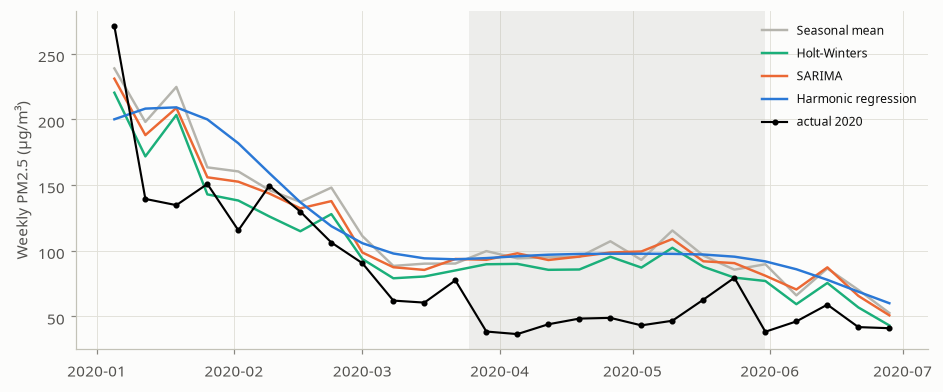

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for m, c in [("Seasonal mean", NEUTRAL), ("Holt-Winters", AQUA), ("SARIMA", ORANGE), ("Harmonic regression", BLUE)]:
    ax.plot(idx20, np.exp(f20[m]["mu"]), lw=1.6, color=c, label=m)
ax.plot(idx20, act20, color="black", marker="o", ms=3, lw=1.4, label="actual 2020")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color=NEUTRAL, alpha=0.2, lw=0)
ax.set_ylabel("Weekly PM2.5 (µg/m³)"); ax.legend(fontsize=8); savefig(fig, "16_lockdown"); plt.show()

In [11]:
def g(t, c): return round(float(t.loc["Harmonic regression", c]), 1)
key["harmonic_2020"] = {c: g(lk, c) for c in lk.columns}
key["best_model_mae_mean_2018_19"] = mae["mean 2018-19"].idxmin()
(RESULTS / "key_numbers_forecast.json").write_text(json.dumps(key, indent=2, default=str)); key

{'sarima_seasonal_ma': -0.988,
 'sarima_seasonal_ma_se': 8.3,
 'lb_all_lag10': 0.0,
 'lb_drop_lag10': 0.597,
 'lb_drop_lag26': 0.133,
 'lb_drop_lag52': 0.02,
 'oneweek': {'Persistence': 30.69,
  'Seasonal mean': 24.79,
  'Harmonic, no weather': 22.39,
  "+ last week's weather": 23.0,
  '+ same-week weather (oracle)': 20.94},
 'lockdown_gap_range': [-49.9, -43.5],
 'harmonic_2020': {'MAE Jan-Feb 2020': 44.9,
  'bias Jan-Mar 2020 (%)': -17.6,
  'lockdown gap (%)': -49.4,
  'gap after removing pre-lockdown bias (%)': -38.6,
  'actual lockdown mean': 48.7,
  'forecast lockdown mean': 96.2,
  'same weeks of 2019 (%)': -14.8,
  'typical 10-week gap 2017-19: 5th pct': -30.6,
  'typical 10-week gap 2017-19: 95th pct': 23.9},
 'best_model_mae_mean_2018_19': 'SARIMA'}